# 03 Small multiples: groups × corruption × severity, and energy as an attribute

Per WordNet group (n = 2 × classes in the group). Energy comes from the AKD1000 power meter (`results_card/energy.csv`): one measurement per condition, so no interval. Tests H5, H7.

In [1]:
%matplotlib inline
import sys
import warnings

warnings.filterwarnings("ignore")
sys.path.insert(0, ".")

In [2]:
# shared setup for all three notebooks, so not every name is used in each
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd  # noqa: F401

from aiv.load import CORRUPTIONS, GROUPS, NAMES, OUTCOMES, SEVERITIES, paired  # noqa: F401
from aiv.load import GROUP as GROUP_OF, table, wordnet_distance  # noqa: F401
from aiv.stats import paired_diff, wilson  # noqa: F401

RUN = "card"                      # "card" = AKD1000 run, "sim" = software simulator run
W = paired(RUN)
COND = [(c, s) for c in CORRUPTIONS for s in SEVERITIES]
COL = dict(zip(OUTCOMES, ["#d9d9d9", "#d62728", "#1f77b4", "#7f7f7f", "#ff7f0e"]))
print(f"run = {RUN} | {W.image_id.nunique()} images x {len(COND)} conditions = {len(W):,} rows | "
      f"{W.label.nunique()} classes in {len(GROUPS)} WordNet groups")

run = card | 2000 images x 15 conditions = 30,000 rows | 1000 classes in 14 WordNet groups


## Accuracy per group, both models
Wilson bands; groups ordered by size.

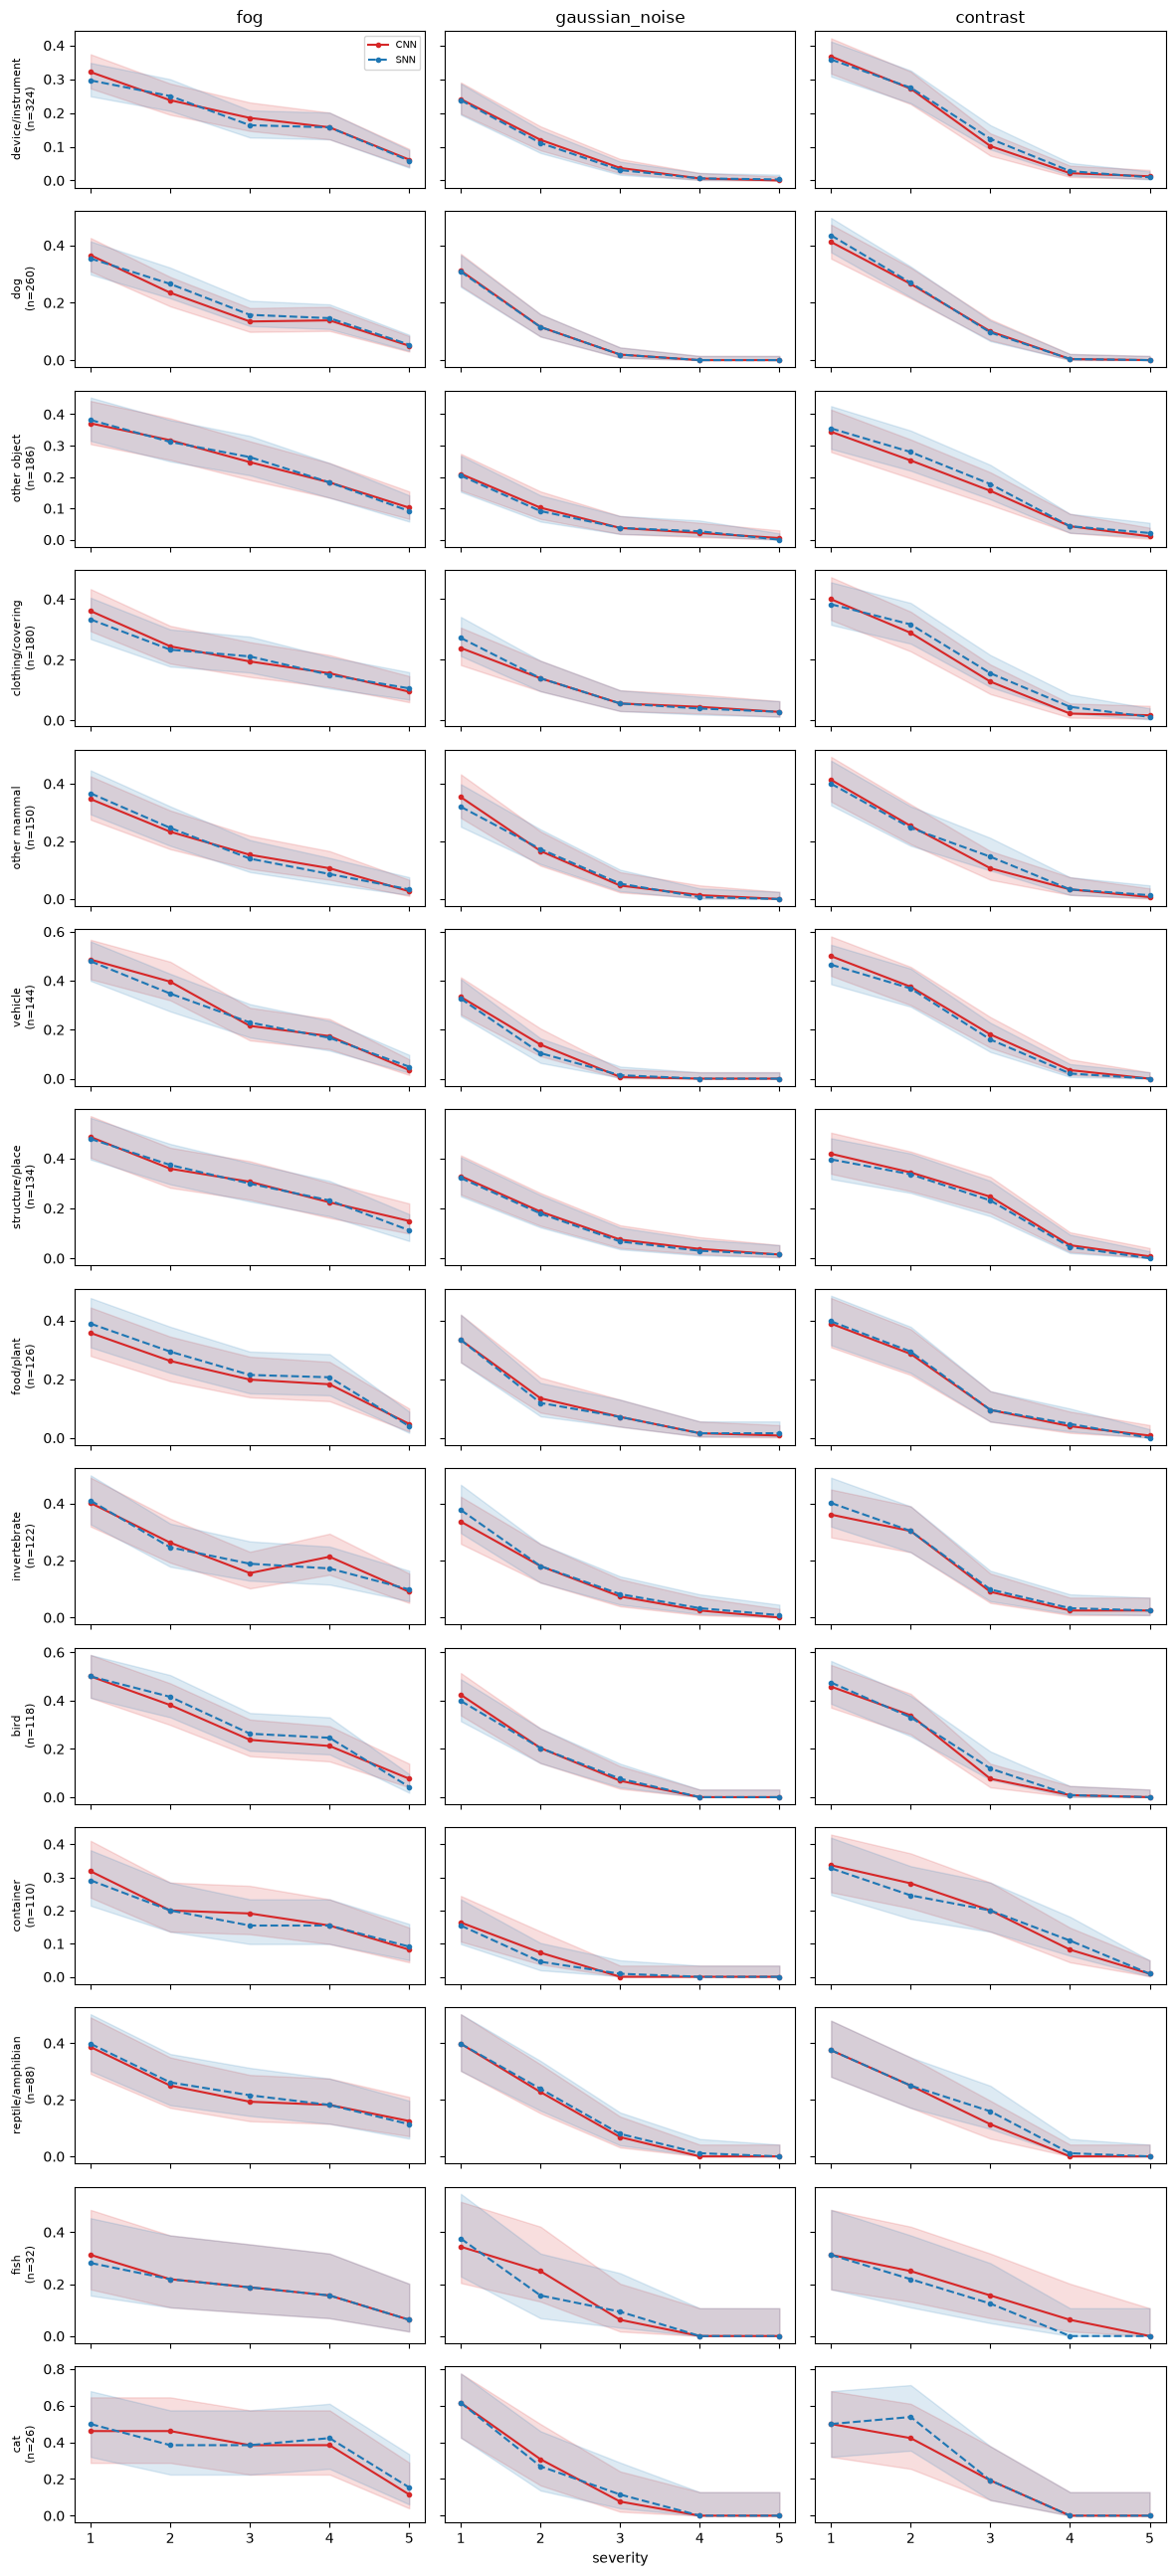

In [3]:
fig, axs = plt.subplots(len(GROUPS), 3, figsize=(12, 26), sharex=True, sharey="row")
for i, g in enumerate(GROUPS):
    for j, corr in enumerate(CORRUPTIONS):
        d = W[(W.group == g) & (W.corruption == corr)].groupby("severity")
        for m, col, ls in (("cnn", "#d62728", "-"), ("snn", "#1f77b4", "--")):
            k, n = d[f"{m}_ok"].sum(), d.size()
            lo, hi = wilson(k, n)
            axs[i, j].plot(k.index, k / n, ls, color=col, marker="o", ms=3, label=m.upper())
            axs[i, j].fill_between(k.index, lo, hi, color=col, alpha=.15)
        if j == 0:
            axs[i, j].set_ylabel(f"{g}\n(n={int(n.iloc[0])})", fontsize=8)
        if i == 0:
            axs[i, j].set_title(corr)
axs[0, 0].legend(fontsize=7)
axs[-1, 1].set_xlabel("severity")
plt.tight_layout()
plt.show()

## Agreement per group × severity
Cell = share of images where CNN and SNN give the same class (± half-width of the Wilson interval).

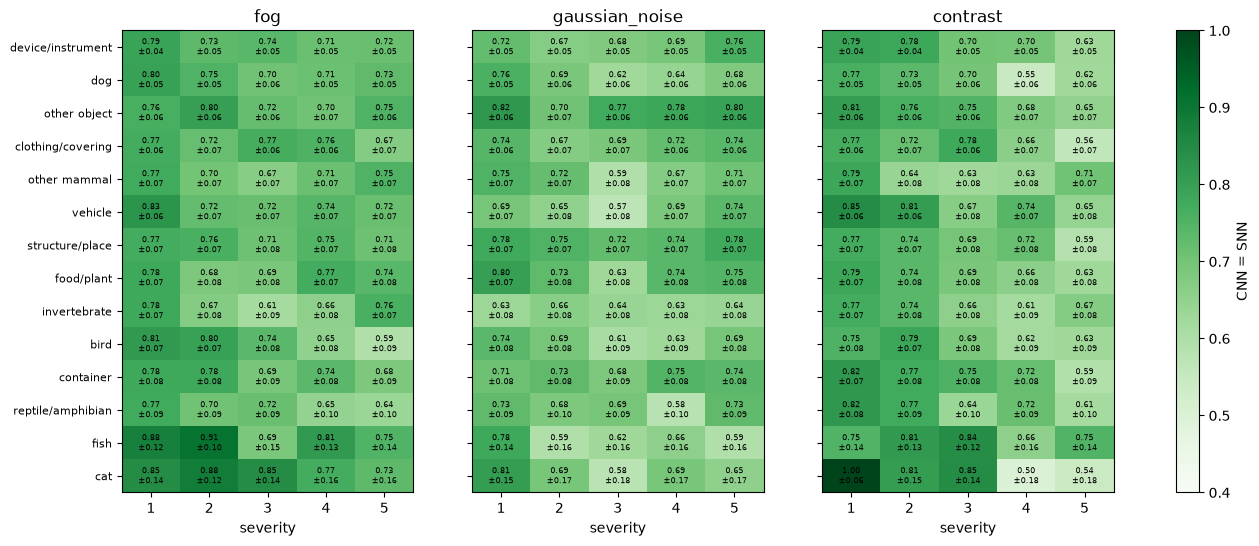

In [4]:
fig, axs = plt.subplots(1, 3, figsize=(16, 6), sharey=True)
for ax, corr in zip(axs, CORRUPTIONS):
    d = W[W.corruption == corr]
    k = d.pivot_table(index="group", columns="severity", values="agree", aggfunc="sum").reindex(GROUPS)
    n = d.pivot_table(index="group", columns="severity", values="agree", aggfunc="size").reindex(GROUPS)
    r = k / n
    lo, hi = wilson(k.values, n.values)
    im = ax.imshow(r.values, cmap="Greens", vmin=.4, vmax=1, aspect="auto")
    for (i, j), v in np.ndenumerate(r.values):
        ax.text(j, i, f"{v:.2f}\n±{(hi[i, j] - lo[i, j]) / 2:.2f}", ha="center", va="center", fontsize=6)
    ax.set_xticks(range(5))
    ax.set_xticklabels(SEVERITIES)
    ax.set_title(corr)
    ax.set_xlabel("severity")
axs[0].set_yticks(range(len(GROUPS)))
axs[0].set_yticklabels(GROUPS, fontsize=8)
fig.colorbar(im, ax=axs, label="CNN = SNN")
plt.show()

## Energy per inference as an attribute of the divergence
Left: AKD1000 energy per frame vs severity. Right: the same numbers against agreement and SNN accuracy of the condition. The card's floor power (idle, ~924 mW in the hardware check) is included, so most of the energy is time × floor power, not activity.

source: AKD1000 power meter, model.statistics after model.predict on chunks of 250, mJ/frame incl. floor power


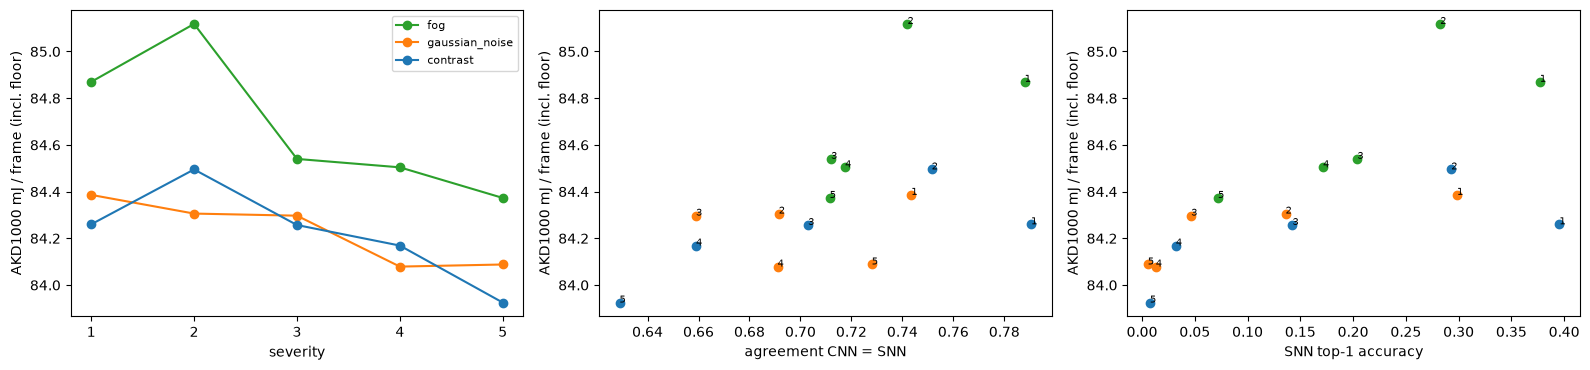

fog             range 84.37–85.12 mJ, Spearman(severity) = -0.90
gaussian_noise  range 84.08–84.39 mJ, Spearman(severity) = -0.90
contrast        range 83.92–84.50 mJ, Spearman(severity) = -0.90
all: max/min = 1.4% spread


In [5]:
from scipy.stats import spearmanr

E = table("energy.csv", "card")
print("source:", E.source.iloc[0])
E = E.merge(W.groupby(["corruption", "severity"]).agg(agree=("agree", "mean"), snn=("snn_ok", "mean"))
            .reset_index(), on=["corruption", "severity"])
fig, axs = plt.subplots(1, 3, figsize=(16, 3.8))
for corr, col in zip(CORRUPTIONS, ["#2ca02c", "#ff7f0e", "#1f77b4"]):
    e = E[E.corruption == corr]
    axs[0].plot(e.severity, e.energy_per_inference, "o-", color=col, label=corr)
    axs[1].scatter(e.agree, e.energy_per_inference, color=col, label=corr)
    axs[2].scatter(e.snn, e.energy_per_inference, color=col, label=corr)
    for _, r in e.iterrows():
        axs[1].annotate(int(r.severity), (r.agree, r.energy_per_inference), fontsize=7)
        axs[2].annotate(int(r.severity), (r.snn, r.energy_per_inference), fontsize=7)
axs[0].set_xlabel("severity")
axs[0].set_xticks(SEVERITIES)
axs[1].set_xlabel("agreement CNN = SNN")
axs[2].set_xlabel("SNN top-1 accuracy")
for ax in axs:
    ax.set_ylabel("AKD1000 mJ / frame (incl. floor)")
axs[0].legend(fontsize=8)
plt.tight_layout()
plt.show()
for corr in CORRUPTIONS:
    e = E[E.corruption == corr]
    r = spearmanr(e.severity, e.energy_per_inference)
    print(f"{corr:15s} range {e.energy_per_inference.min():.2f}–{e.energy_per_inference.max():.2f} mJ, "
          f"Spearman(severity) = {r.statistic:+.2f}")
print(f"all: max/min = {E.energy_per_inference.max() / E.energy_per_inference.min() - 1:.1%} spread")

Layer specification of the converted model (`results_sim/layers.csv`): context for Phase II. It lists layer sizes and bit widths only; per-image activity is not exported yet.

In [6]:
table("layers.csv", "sim")

,index,name,layer_type,input_dims,output_dims,input_bits,weights_bits,act_bits,activation
0,0,conv_0,InputConvolutional,224x224x3,112x112x16,8,8,4,1
1,1,conv_1,Convolutional,112x112x16,112x112x32,4,4,4,1
2,2,conv_2,Convolutional,112x112x32,56x56x64,4,4,4,1
3,3,conv_3,Convolutional,56x56x64,56x56x64,4,4,4,1
4,4,separable_4,SeparableConvolutional,56x56x64,28x28x128,4,4,4,1
5,5,separable_5,SeparableConvolutional,28x28x128,28x28x128,4,4,4,1
6,6,separable_6,SeparableConvolutional,28x28x128,14x14x256,4,4,4,1
7,7,separable_7,SeparableConvolutional,14x14x256,14x14x256,4,4,4,1
8,8,separable_8,SeparableConvolutional,14x14x256,14x14x256,4,4,4,1
9,9,separable_9,SeparableConvolutional,14x14x256,14x14x256,4,4,4,1


## Findings (03 small multiples and energy)

Run: `results_card/` (AKD1000). Group intervals are wide: 26–324 images per group per
condition.

1. **Groups degrade in parallel for both models.** In every group × corruption panel the CNN
   and SNN accuracy bands overlap at every severity. No group shows an SNN-specific weakness.
2. **Agreement varies by group, but within noise.** Per-group agreement ranges from
   0.50 to 1.00, but half-widths are ±0.04–0.18, and the extremes are all in the smallest groups
   (cat, fish: 26–32 images). The visible lows (cat contrast 4: 0.50 ± 0.18;
   dog contrast 4: 0.55 ± 0.06) are single cells, not a pattern across severities. H5
   (fine-grained animals diverge faster) is not supported.
3. **Energy per inference barely moves (H7: direction yes, effect tiny).** AKD1000 energy is
   83.9–85.1 mJ/frame across all 15 conditions, a 1.4 % spread. Within each corruption it falls
   with severity (Spearman −0.9, p = 0.04 for each, n = 5), and fog costs most at every
   severity. This fits sparser input → fewer events, but:
   - each value is one measurement over 2000 images, so there are no intervals
   - the numbers include floor power (~924 mW idle out of ~958 mW in the hardware check), so
     only a few percent of the energy depends on activity at all
   - energy and accuracy both fall with severity, so their correlation says nothing extra
   For the Phase I question (where do CNN and SNN diverge), energy does not separate the
   conditions in any useful way.
4. **Phase II hook:** `results_sim/layers.csv` holds the layer specs (14 layers, 4-bit
   activations, one 1-bit output layer), not per-image activity. Per-layer non-zero counts
   are needed to test the "fewer events" guess behind H7 and the near-tie guess behind H3.
